
# EEG Assignment 02

In [50]:
%pip install -q -U mne scipy matplotlib pandas

In [51]:
from pathlib import Path
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mne
from scipy import signal
from scipy.integrate import trapezoid
from scipy.stats import theilslopes
from scipy.signal import welch
from scipy.signal import spectrogram

print("MNE version:", mne.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

MNE version: 1.13.2
NumPy version: 2.1.3
Pandas version: 3.0.6


In [52]:
%pip install matplotlib==3.9.2

  Using cached matplotlib-3.9.2-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
Using cached matplotlib-3.9.2-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (8.3 MB)
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.11.2
    Uninstalling matplotlib-3.11.2:
      Successfully uninstalled matplotlib-3.11.2


# 1. Load and Verify

In [53]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

EEG_PATH = Path("/content/drive/MyDrive/Colab Notebooks")

print("Folder exists:", EEG_PATH.exists())

edf_files = sorted(EEG_PATH.glob("*.edf"))

print("Number of EDF files:", len(edf_files))
for f in edf_files:
    print(f.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
Number of EDF files: 4
SS_High_2023-04-30_12-09-20_Segment_0.edf
SS_Low_2023-04-30_12-30-49_Segment_0.edf
SS_Medium_2023-04-30_12-41-47_Segment_0.edf
SS_Rest_2023-04-30_11-31-50_Segment_0.edf


In [54]:
for f in edf_files:
    raw = mne.io.read_raw_edf(str(f), preload=False, verbose=False)

    print(f"\nFile: {f.name}")
    print("Sampling frequency:", raw.info["sfreq"], "Hz")
    print("Number of channels:", len(raw.ch_names))
    print("Duration:", round(raw.n_times / raw.info["sfreq"], 2), "seconds")
    print("Channel names:", raw.ch_names)

    raw.close()


File: SS_High_2023-04-30_12-09-20_Segment_0.edf
Sampling frequency: 512.0 Hz
Number of channels: 27
Duration: 388.0 seconds
Channel names: ['EEG Fp1-M1', 'EEG Fp2-M1', 'EEG F7-M1', 'EEG F3-M1', 'EEG Fz-M1', 'EEG F4-M1', 'EEG F8-M1', 'EEG M1-M1', 'EEG T7-M1', 'EEG C3-M1', 'EEG Cz-M1', 'EEG C4-M1', 'EEG T8-M1', 'EEG P7-M1', 'EEG P3-M1', 'EEG Pz-M1', 'EEG P4-M1', 'EEG P8-M1', 'EEG O1-M1', 'EEG O2-M1', 'EEG EOG-M1', 'EEG FC3-M1', 'EEG FCz-M1', 'EEG FC4-M1', 'EEG CP3-M1', 'EEG CP4-M1', 'EEG Oz-M1']

File: SS_Low_2023-04-30_12-30-49_Segment_0.edf
Sampling frequency: 512.0 Hz
Number of channels: 27
Duration: 256.0 seconds
Channel names: ['EEG Fp1-M1', 'EEG Fp2-M1', 'EEG F7-M1', 'EEG F3-M1', 'EEG Fz-M1', 'EEG F4-M1', 'EEG F8-M1', 'EEG M1-M1', 'EEG T7-M1', 'EEG C3-M1', 'EEG Cz-M1', 'EEG C4-M1', 'EEG T8-M1', 'EEG P7-M1', 'EEG P3-M1', 'EEG Pz-M1', 'EEG P4-M1', 'EEG P8-M1', 'EEG O1-M1', 'EEG O2-M1', 'EEG EOG-M1', 'EEG FC3-M1', 'EEG FCz-M1', 'EEG FC4-M1', 'EEG CP3-M1', 'EEG CP4-M1', 'EEG Oz-M1']



In [55]:
raws = {}

for f in edf_files:
    raw = mne.io.read_raw_edf(
        str(f),
        preload=True,
        verbose=False
    )

    rename_map = {
        ch: ch.replace("EEG ", "").replace("-M1", "")
        for ch in raw.ch_names
    }

    raw.rename_channels(rename_map)

    if "M1" in raw.ch_names:
        raw.drop_channels(["M1"])

    if "EOG" in raw.ch_names:
        raw.set_channel_types({"EOG": "eog"})

    condition = f.name.split("_")[1]
    raws[condition] = raw

    print(
        condition,
        "| Channels:", len(raw.ch_names),
        "| Sampling rate:", raw.info["sfreq"],
        "| EOG present:", "EOG" in raw.ch_names
    )
    print(raw.ch_names)

High | Channels: 26 | Sampling rate: 512.0 | EOG present: True
['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2', 'EOG', 'FC3', 'FCz', 'FC4', 'CP3', 'CP4', 'Oz']
Low | Channels: 26 | Sampling rate: 512.0 | EOG present: True
['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2', 'EOG', 'FC3', 'FCz', 'FC4', 'CP3', 'CP4', 'Oz']
Medium | Channels: 26 | Sampling rate: 512.0 | EOG present: True
['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2', 'EOG', 'FC3', 'FCz', 'FC4', 'CP3', 'CP4', 'Oz']
Rest | Channels: 26 | Sampling rate: 512.0 | EOG present: True
['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2', 'EOG', 'FC3', 'FCz', 'FC4', 'CP3', 'CP4', 'Oz']


In [56]:
montage = mne.channels.make_standard_montage("standard_1020")

for condition, raw in raws.items():
    raw.set_montage(
        montage,
        match_case=False,
        on_missing="warn"
    )

    print(f"\n{condition}")
    print("Channels:", len(raw.ch_names))
    print("Montage set.")


High
Channels: 26
Montage set.

Low
Channels: 26
Montage set.

Medium
Channels: 26
Montage set.

Rest
Channels: 26
Montage set.


/tmp/ipykernel_2834/2315658332.py:1: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")



Condition: High
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


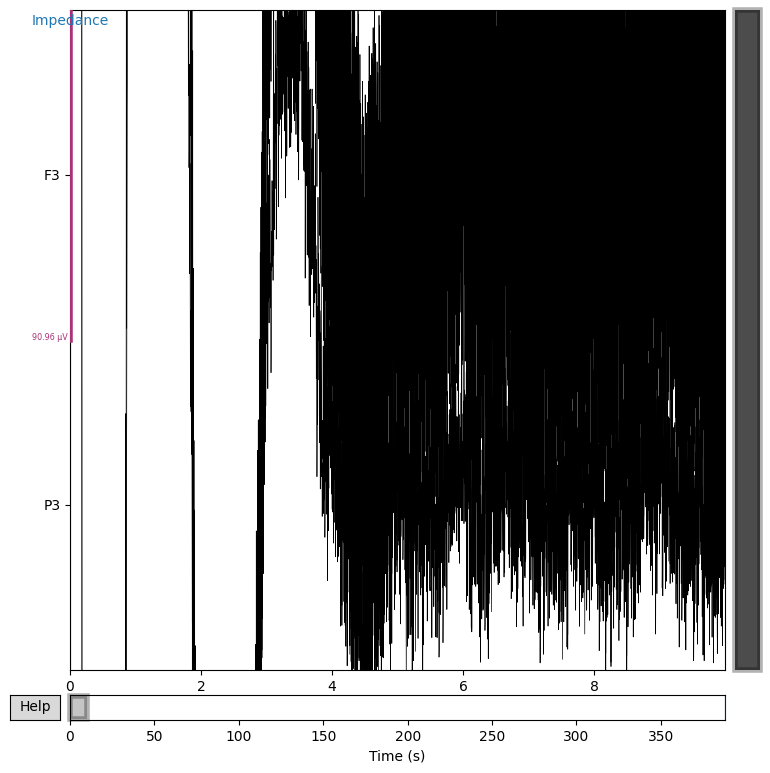

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


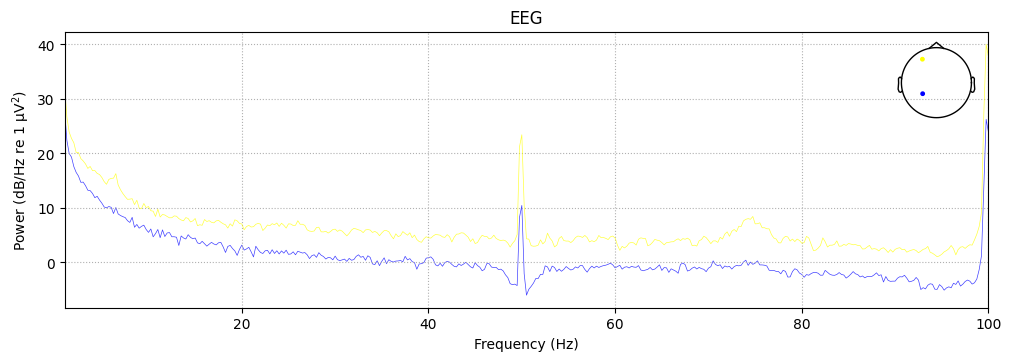


Condition: Low
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


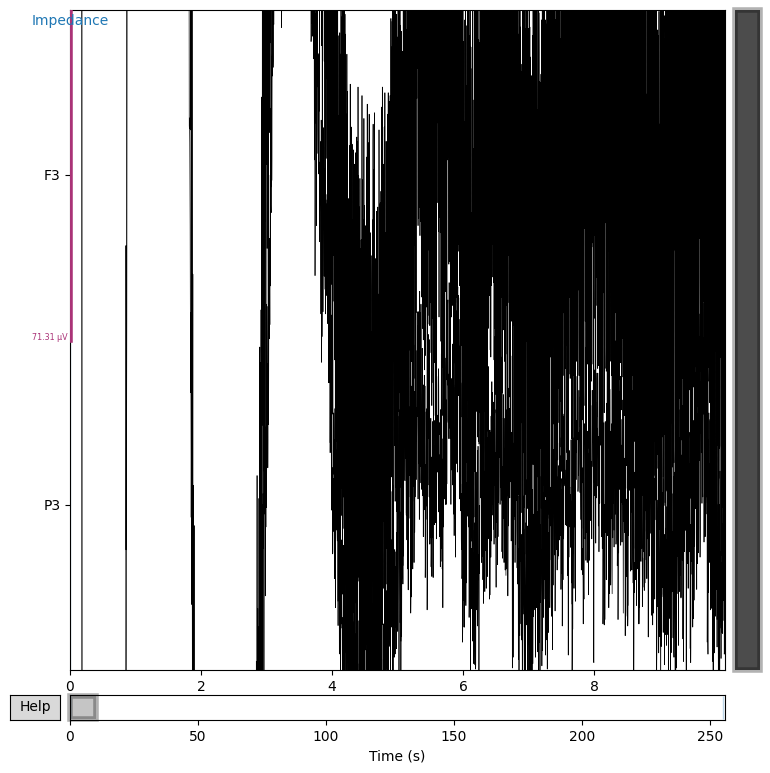

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


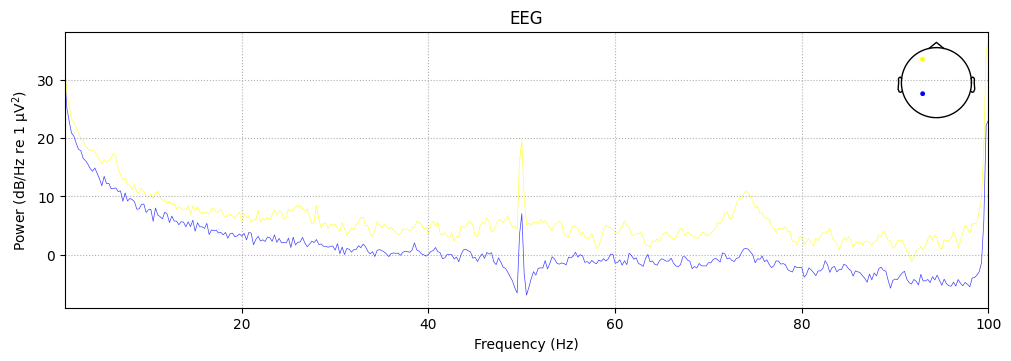


Condition: Medium
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


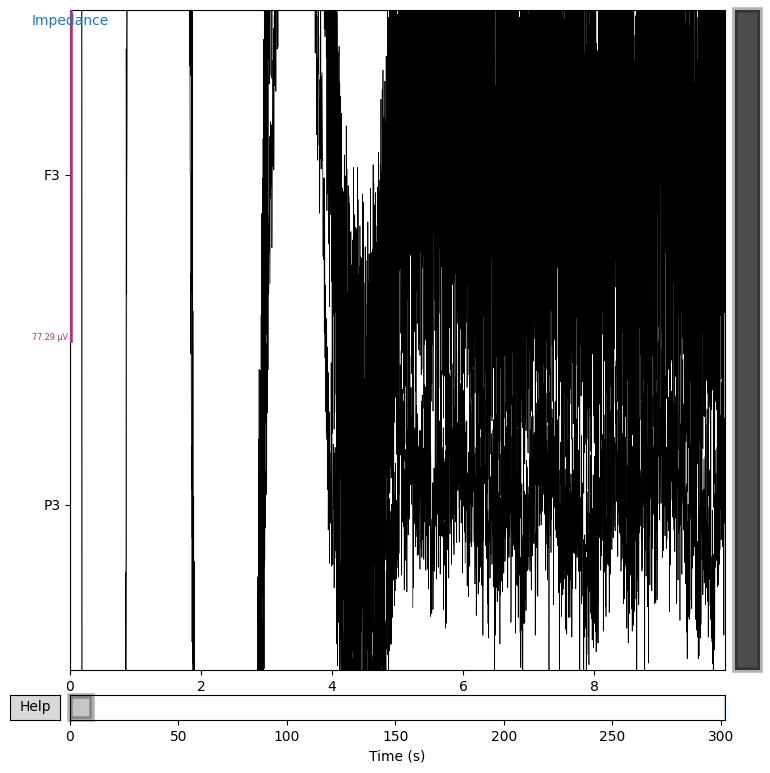

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


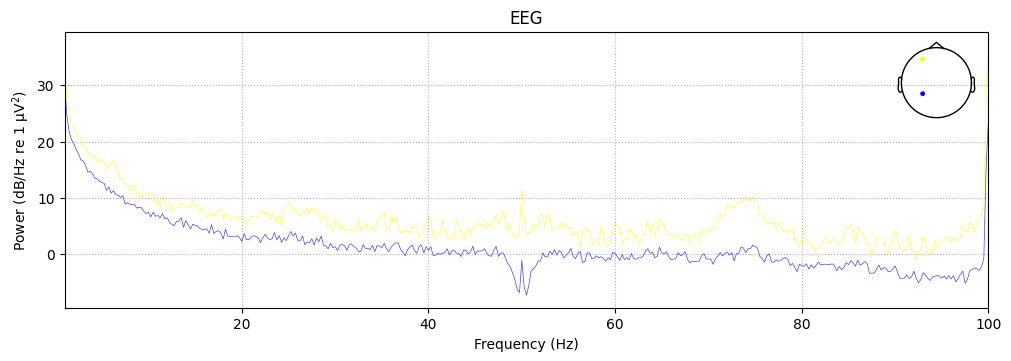


Condition: Rest
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


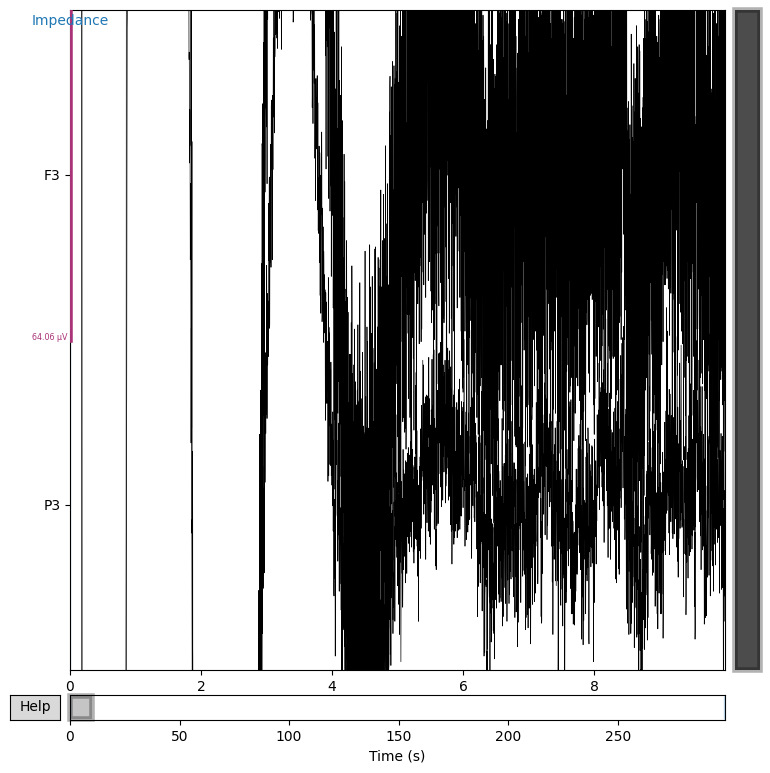

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


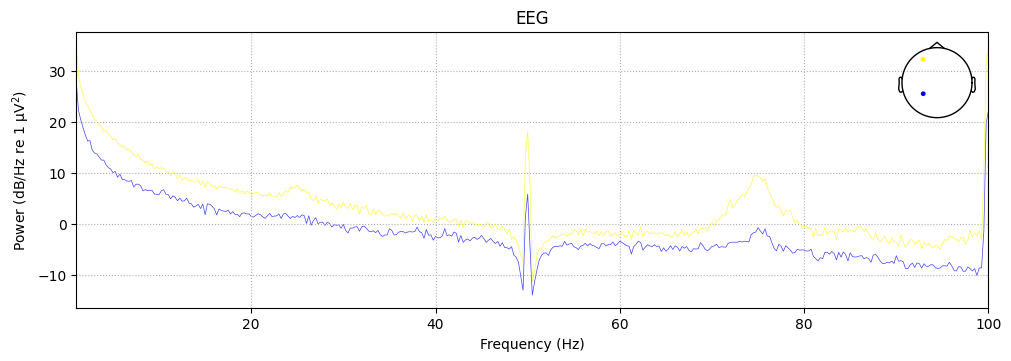


Saved images:
Bandpass_PSD_four_conditions.png
Four_filter_magnitude_responses.png
High_EEG_signals.png
High_PSD.png
High_bandpass_PSD.png
High_four_filter_time_comparison.png
High_notch_comparison.png
High_raw_EEG.png
High_raw_PSD.png
High_scalp_maps.png
Low_EEG_signals.png
Low_PSD.png
Low_bandpass_PSD.png
Low_four_filter_time_comparison.png
Low_notch_comparison.png
Low_raw_EEG.png
Low_raw_PSD.png
Low_scalp_maps.png
Mean_Absolute_Band_Power_Comparison.png
Medium_EEG_signals.png
Medium_PSD.png
Medium_bandpass_PSD.png
Medium_four_filter_time_comparison.png
Medium_notch_comparison.png
Medium_raw_EEG.png
Medium_raw_PSD.png
Medium_scalp_maps.png
Raw_Notch_Bandpass_time_comparison.png
Rest_EEG_signals.png
Rest_PSD.png
Rest_bandpass_PSD.png
Rest_four_filter_time_comparison.png
Rest_notch_comparison.png
Rest_raw_EEG.png
Rest_raw_PSD.png
Rest_scalp_maps.png


In [57]:
FIGURES_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Assignment-02/figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

selected_channels = ["F3", "P3"]

for condition, raw in raws.items():
    print(f"\nCondition: {condition}")

    fig = raw.plot(
        picks=selected_channels,
        duration=10,
        start=0,
        n_channels=2,
        scalings="auto",
        show=False
    )
    fig.savefig(
        FIGURES_DIR / f"{condition}_EEG_signals.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    spectrum = raw.compute_psd(
        method="welch",
        picks=selected_channels,
        fmin=1,
        fmax=100,
        n_fft=2048
    )

    fig = spectrum.plot(show=False)
    fig.savefig(
        FIGURES_DIR / f"{condition}_PSD.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("\nSaved images:")
for file in sorted(FIGURES_DIR.glob("*.png")):
    print(file.name)

In [58]:
FIGURES_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Assignment-02/figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

selected_channels = ["F3", "P3"]

for condition, raw in raws.items():

    fig = raw.plot(
        picks=selected_channels,
        duration=10,
        start=0,
        n_channels=2,
        scalings="auto",
        show=False
    )

    fig.savefig(
        FIGURES_DIR / f"{condition}_raw_EEG.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(fig)

    spectrum = raw.compute_psd(
        method="welch",
        picks=selected_channels,
        fmin=1,
        fmax=100,
        n_fft=2048
    )

    fig = spectrum.plot(show=False)

    fig.savefig(
        FIGURES_DIR / f"{condition}_raw_PSD.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(fig)

print("Saved files:")
for file in sorted(FIGURES_DIR.glob("*.png")):
    print(file.name)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Saved files:
Bandpass_PSD_four_conditions.png
Four_filter_magnitude_responses.png
High_EEG_signals.png
High_PSD.png
High_bandpass_PSD.png
High_four_filter_time_comparison.png
High_notch_comparison.png
High_raw_EEG.png
High_raw_PSD.png
H

In [59]:
raws_notch = {}

for condition, raw in raws.items():
    filtered = raw.copy()
    filtered.notch_filter(
        freqs=[50],
        picks="eeg",
        method="fir",
        phase="zero"
    )
    raws_notch[condition] = filtered
    print(f"{condition}: 50 Hz notch filter applied")

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 3381 samples (6.604 s)

High: 50 Hz notch filter applied
Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff freque

Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)


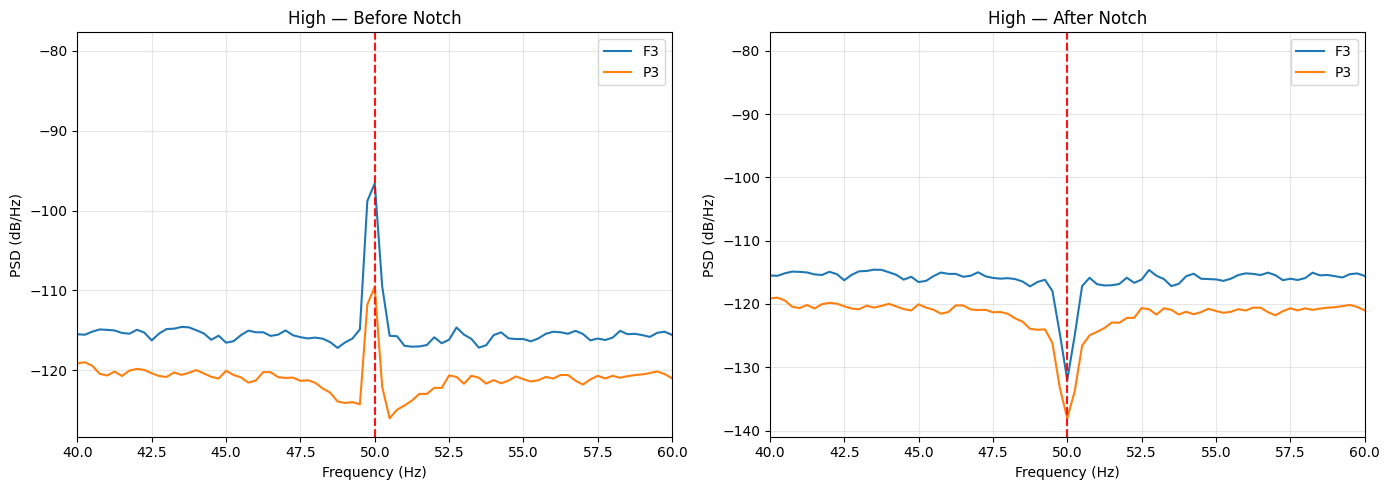

Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)


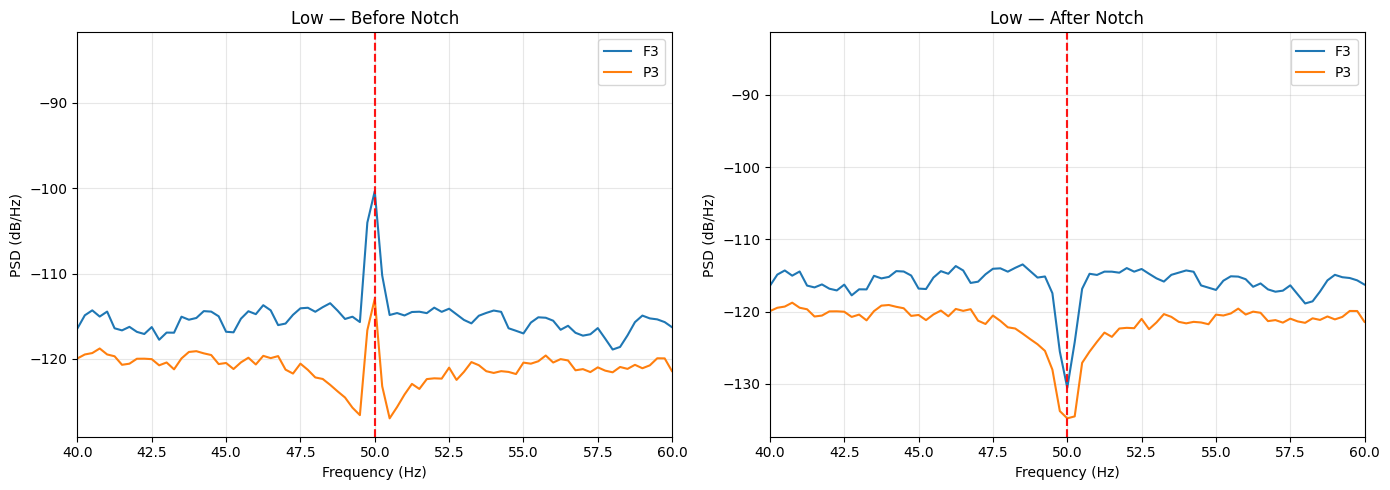

Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)


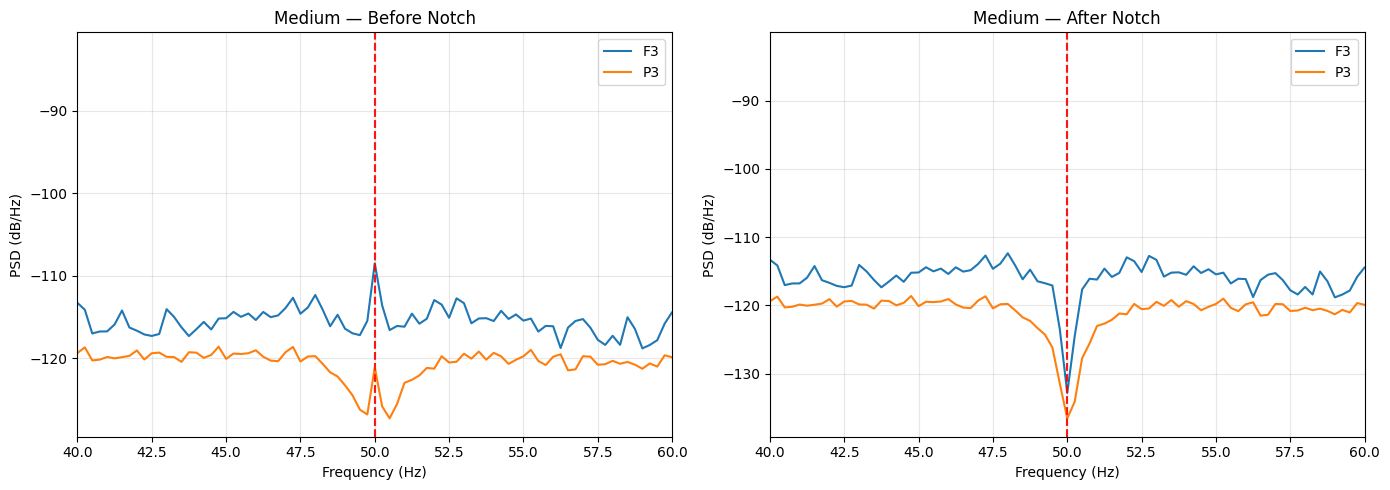

Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)


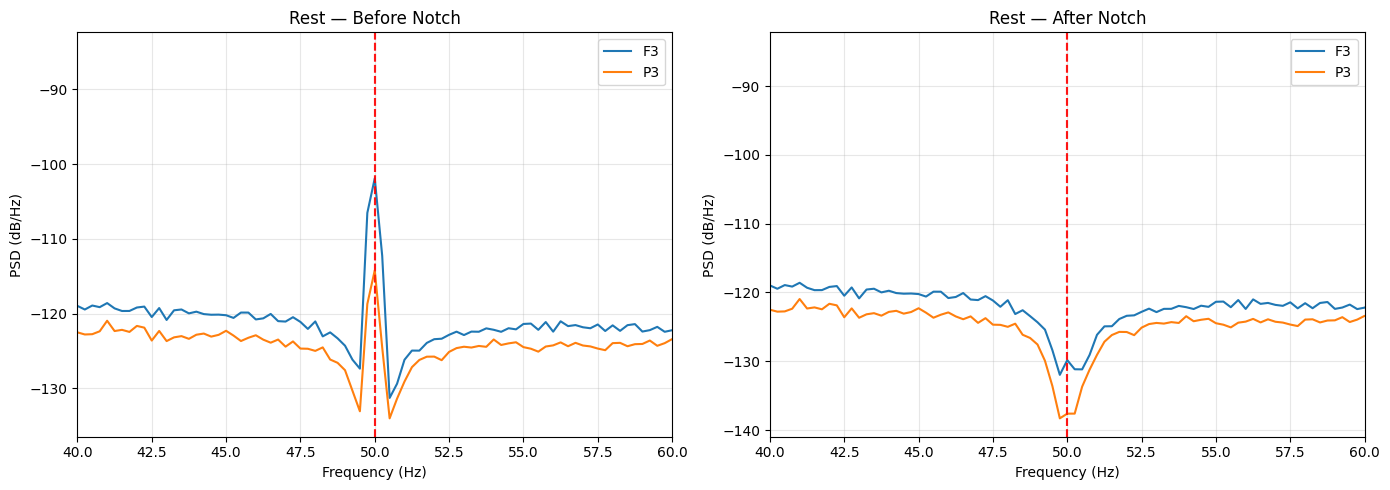

Saved Notch comparison images:
High_notch_comparison.png
Low_notch_comparison.png
Medium_notch_comparison.png
Rest_notch_comparison.png


In [60]:
FIGURES_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Assignment-02/figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for condition in raws.keys():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for channel in ["F3", "P3"]:
        for ax, dataset, title in [
            (axes[0], raws[condition], "Before Notch"),
            (axes[1], raws_notch[condition], "After Notch"),
        ]:
            spectrum = dataset.compute_psd(
                method="welch",
                picks=[channel],
                fmin=1,
                fmax=100,
                n_fft=2048
            )

            psd_db = 10 * np.log10(
                np.maximum(spectrum.get_data()[0], 1e-20)
            )

            ax.plot(spectrum.freqs, psd_db, label=channel)
            ax.set_title(f"{condition} — {title}")
            ax.set_xlabel("Frequency (Hz)")
            ax.set_ylabel("PSD (dB/Hz)")
            ax.set_xlim(40, 60)
            ax.axvline(50, color="red", linestyle="--", alpha=0.7)
            ax.grid(True, alpha=0.3)
            ax.legend()

    plt.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"{condition}_notch_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Saved Notch comparison images:")
for file in sorted(FIGURES_DIR.glob("*_notch_comparison.png")):
    print(file.name)

In [61]:
raws_clean = {}

for condition, raw in raws_notch.items():
    filtered = raw.copy()

    filtered.filter(
        l_freq=1,
        h_freq=45,
        picks="eeg",
        method="fir",
        phase="zero"
    )

    raws_clean[condition] = filtered
    print(f"{condition}: Notch + 1–45 Hz band-pass applied")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 1691 samples (3.303 s)

High: Notch + 1–45 Hz band-pass applied
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff fre

In [62]:
FIGURES_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Assignment-02/figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for condition, raw in raws_clean.items():
    fig = raw.compute_psd(
        method="welch",
        picks=["F3", "P3"],
        fmin=1,
        fmax=100,
        n_fft=2048
    ).plot(show=False)

    fig.savefig(
        FIGURES_DIR / f"{condition}_bandpass_PSD.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)
    print(f"{condition}: Band-pass PSD saved")

print("Done!")

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
High: Band-pass PSD saved
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Low: Band-pass PSD saved
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Medium: Band-pass PSD saved
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Rest: Band-pass PSD saved
Done!


In [63]:
bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

band_power_results = []

for condition, raw in raws_clean.items():
    eeg_raw = raw.copy().pick("eeg")
    data = eeg_raw.get_data()
    sfreq = eeg_raw.info["sfreq"]
    channel_names = eeg_raw.ch_names

    for i, channel in enumerate(channel_names):
        freqs, psd = welch(
            data[i],
            fs=sfreq,
            nperseg=2048
        )

        total_mask = (freqs >= 1) & (freqs <= 45)
        total_power = np.trapezoid(
            psd[total_mask],
            freqs[total_mask]
        )

        for band, (low, high) in bands.items():
            mask = (freqs >= low) & (freqs < high)

            power = np.trapezoid(
                psd[mask],
                freqs[mask]
            )

            band_power_results.append({
                "Condition": condition,
                "Channel": channel,
                "Band": band,
                "Absolute_Power": power,
                "Relative_Power": (
                    power / total_power
                    if total_power > 0 else np.nan
                )
            })

band_power_df = pd.DataFrame(band_power_results)

csv_path = FIGURES_DIR.parent / "band_power_results.csv"
band_power_df.to_csv(csv_path, index=False)

print("Band power calculated.")
print("Results saved to:", csv_path)
display(band_power_df.head())

Band power calculated.
Results saved to: /content/drive/MyDrive/Colab Notebooks/Assignment-02/band_power_results.csv


,Condition,Channel,Band,Absolute_Power,Relative_Power
0,High,Fp1,Delta,1.466811e-10,0.442088
1,High,Fp1,Theta,6.382668e-11,0.192370
2,High,Fp1,Alpha,2.086170e-11,0.062876
3,High,Fp1,Beta,5.719488e-11,0.172382
4,High,Fp1,Gamma,3.417978e-11,0.103016


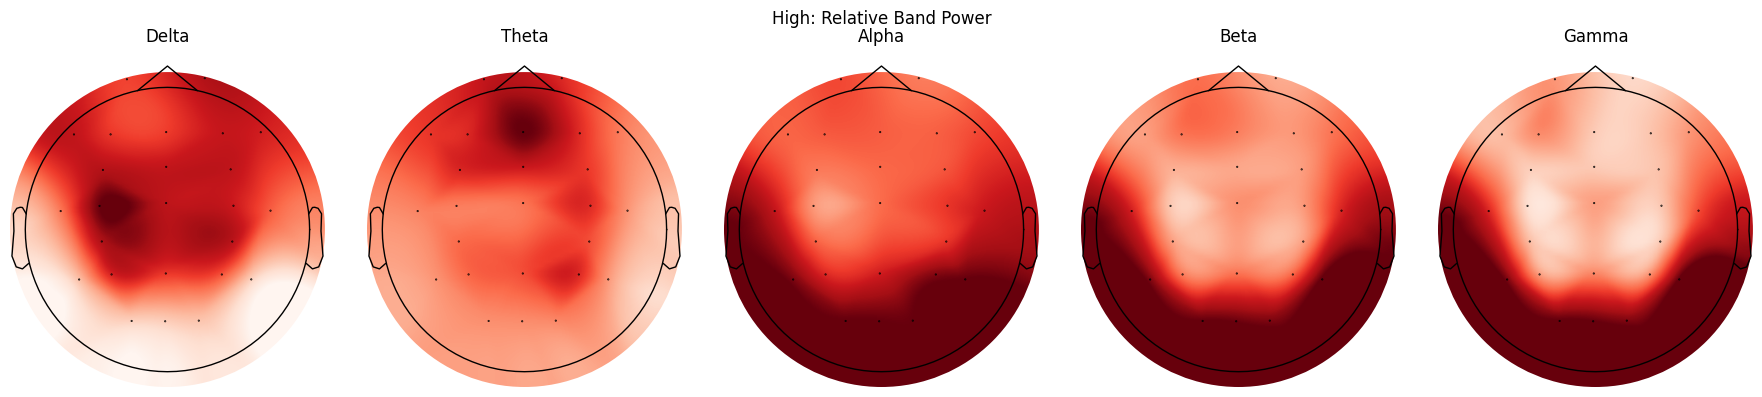

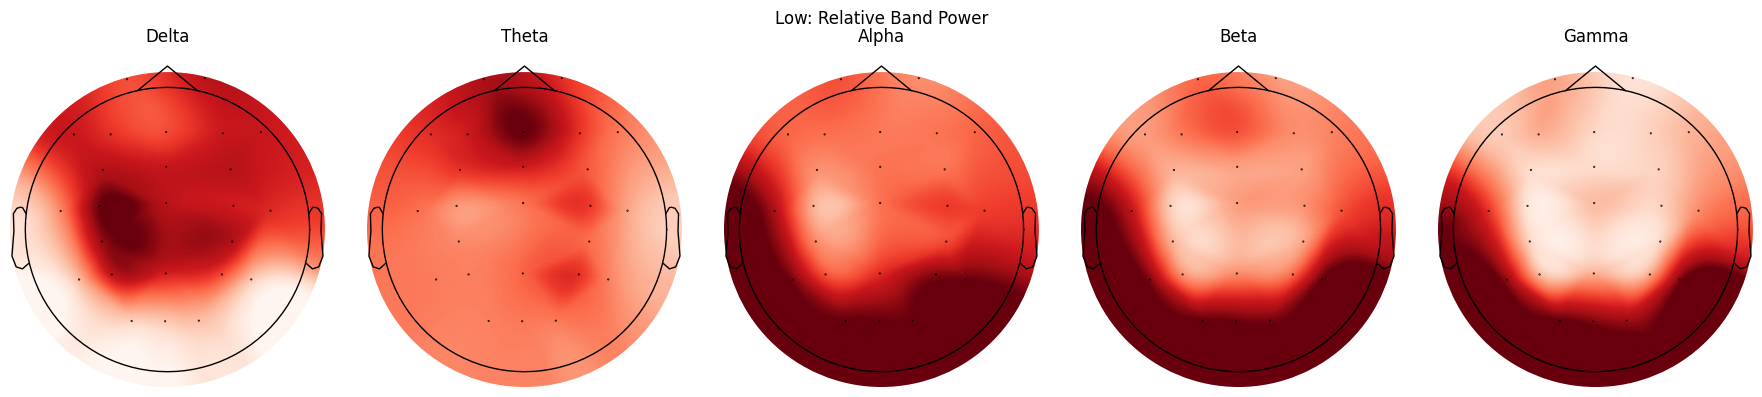

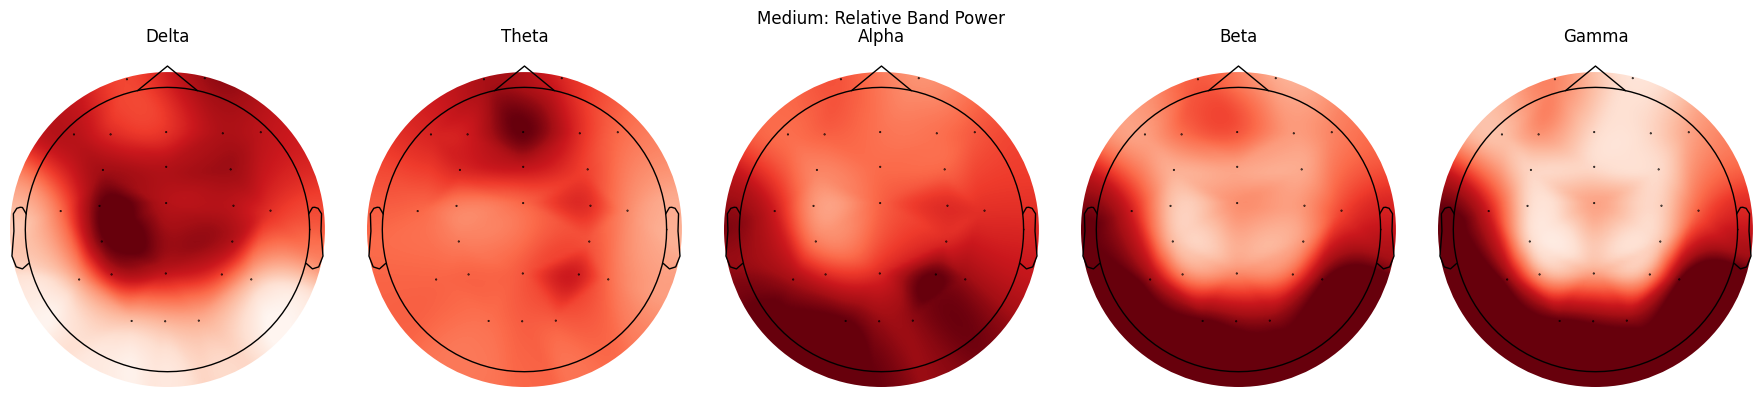

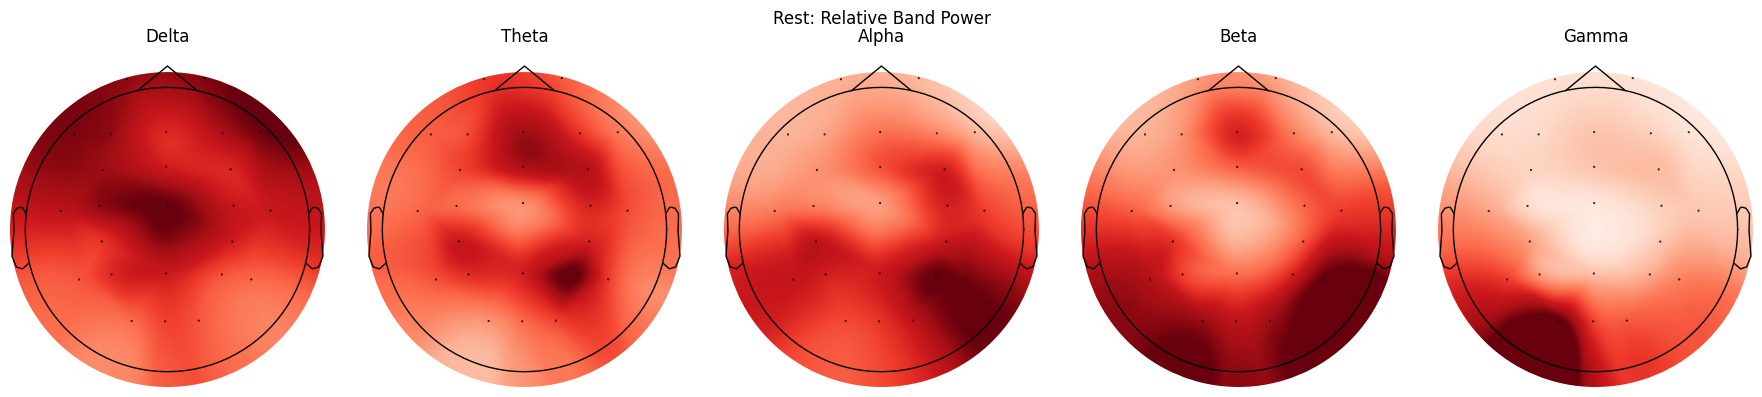

Scalp maps saved.


In [64]:
bands_order = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]

for condition in raws_clean:
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    for ax, band in zip(axes, bands_order):
        subset = band_power_df[
            (band_power_df["Condition"] == condition) &
            (band_power_df["Band"] == band)
        ]

        channel_names = subset["Channel"].tolist()
        values = subset["Relative_Power"].to_numpy()

        info = mne.pick_info(
            raws_clean[condition].info,
            mne.pick_channels(
                raws_clean[condition].ch_names,
                include=channel_names
            )
        )

        value_map = dict(zip(channel_names, values))
        ordered_values = np.array([
            value_map[ch] for ch in info["ch_names"]
        ])

        mne.viz.plot_topomap(
            ordered_values,
            info,
            axes=ax,
            show=False,
            contours=0
        )

        ax.set_title(band)

    fig.suptitle(f"{condition}: Relative Band Power")
    plt.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"{condition}_scalp_maps.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Scalp maps saved.")

In [65]:
for condition in raws:
    print(f"\n{condition}")
    print("Raw:", raws[condition].info["sfreq"], "Hz")
    print("Notch:", condition in raws_notch)
    print("Clean:", condition in raws_clean)

    if condition in raws_clean:
        print("Channels:", len(raws_clean[condition].ch_names))
        print("Duration:", round(raws_clean[condition].n_times /
                                  raws_clean[condition].info["sfreq"], 2), "s")


High
Raw: 512.0 Hz
Notch: True
Clean: True
Channels: 26
Duration: 388.0 s

Low
Raw: 512.0 Hz
Notch: True
Clean: True
Channels: 26
Duration: 256.0 s

Medium
Raw: 512.0 Hz
Notch: True
Clean: True
Channels: 26
Duration: 302.0 s

Rest
Raw: 512.0 Hz
Notch: True
Clean: True
Channels: 26
Duration: 299.0 s


In [66]:
for condition in ["Rest", "Low", "Medium", "High"]:
    print(f"\n--- {condition} ---")

    print("Raw filters:", raws[condition].info["highpass"],
          "to", raws[condition].info["lowpass"], "Hz")

    print("Notch filters:",
          raws_notch[condition].info["highpass"],
          "to", raws_notch[condition].info["lowpass"], "Hz")

    print("Clean filters:",
          raws_clean[condition].info["highpass"],
          "to", raws_clean[condition].info["lowpass"], "Hz")


--- Rest ---
Raw filters: 0.0 to 256.0 Hz
Notch filters: 0.0 to 256.0 Hz
Clean filters: 1.0 to 45.0 Hz

--- Low ---
Raw filters: 0.0 to 256.0 Hz
Notch filters: 0.0 to 256.0 Hz
Clean filters: 1.0 to 45.0 Hz

--- Medium ---
Raw filters: 0.0 to 256.0 Hz
Notch filters: 0.0 to 256.0 Hz
Clean filters: 1.0 to 45.0 Hz

--- High ---
Raw filters: 0.0 to 256.0 Hz
Notch filters: 0.0 to 256.0 Hz
Clean filters: 1.0 to 45.0 Hz


Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)
Effective window size : 4.000 (s)


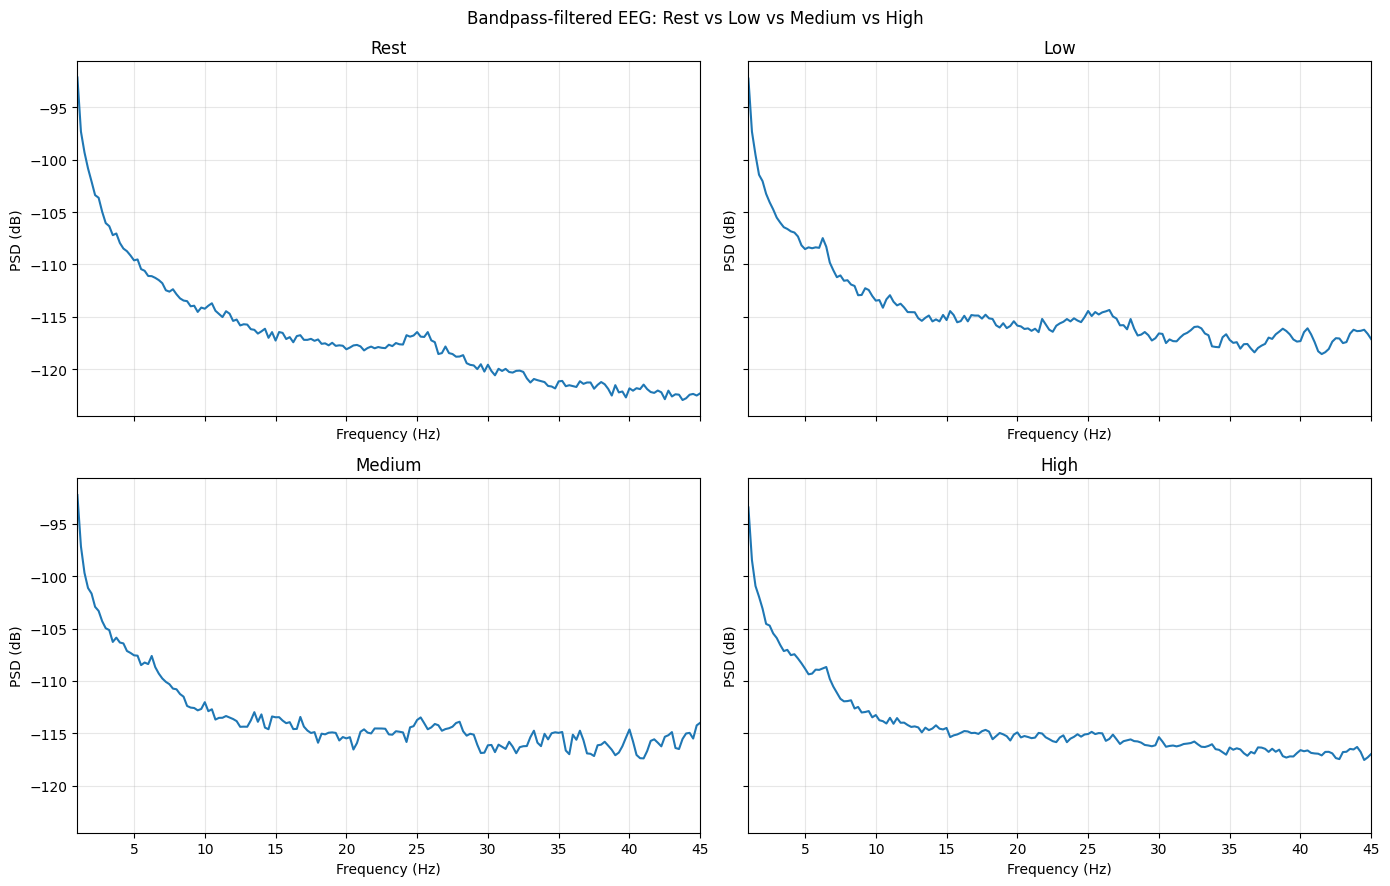

Saved: Bandpass_PSD_four_conditions.png


In [67]:
conditions = ["Rest", "Low", "Medium", "High"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for ax, condition in zip(axes.flat, conditions):
    raw = raws_clean[condition]

    spectrum = raw.compute_psd(
        method="welch",
        fmin=1,
        fmax=45,
        n_fft=2048,
        n_overlap=1024,
        picks="eeg"
    )

    psd, freqs = spectrum.get_data(return_freqs=True)
    mean_psd = psd.mean(axis=0)

    ax.plot(freqs, 10 * np.log10(mean_psd))
    ax.set_title(condition)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB)")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(1, 45)

fig.suptitle("Bandpass-filtered EEG: Rest vs Low vs Medium vs High")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "Bandpass_PSD_four_conditions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved: Bandpass_PSD_four_conditions.png")

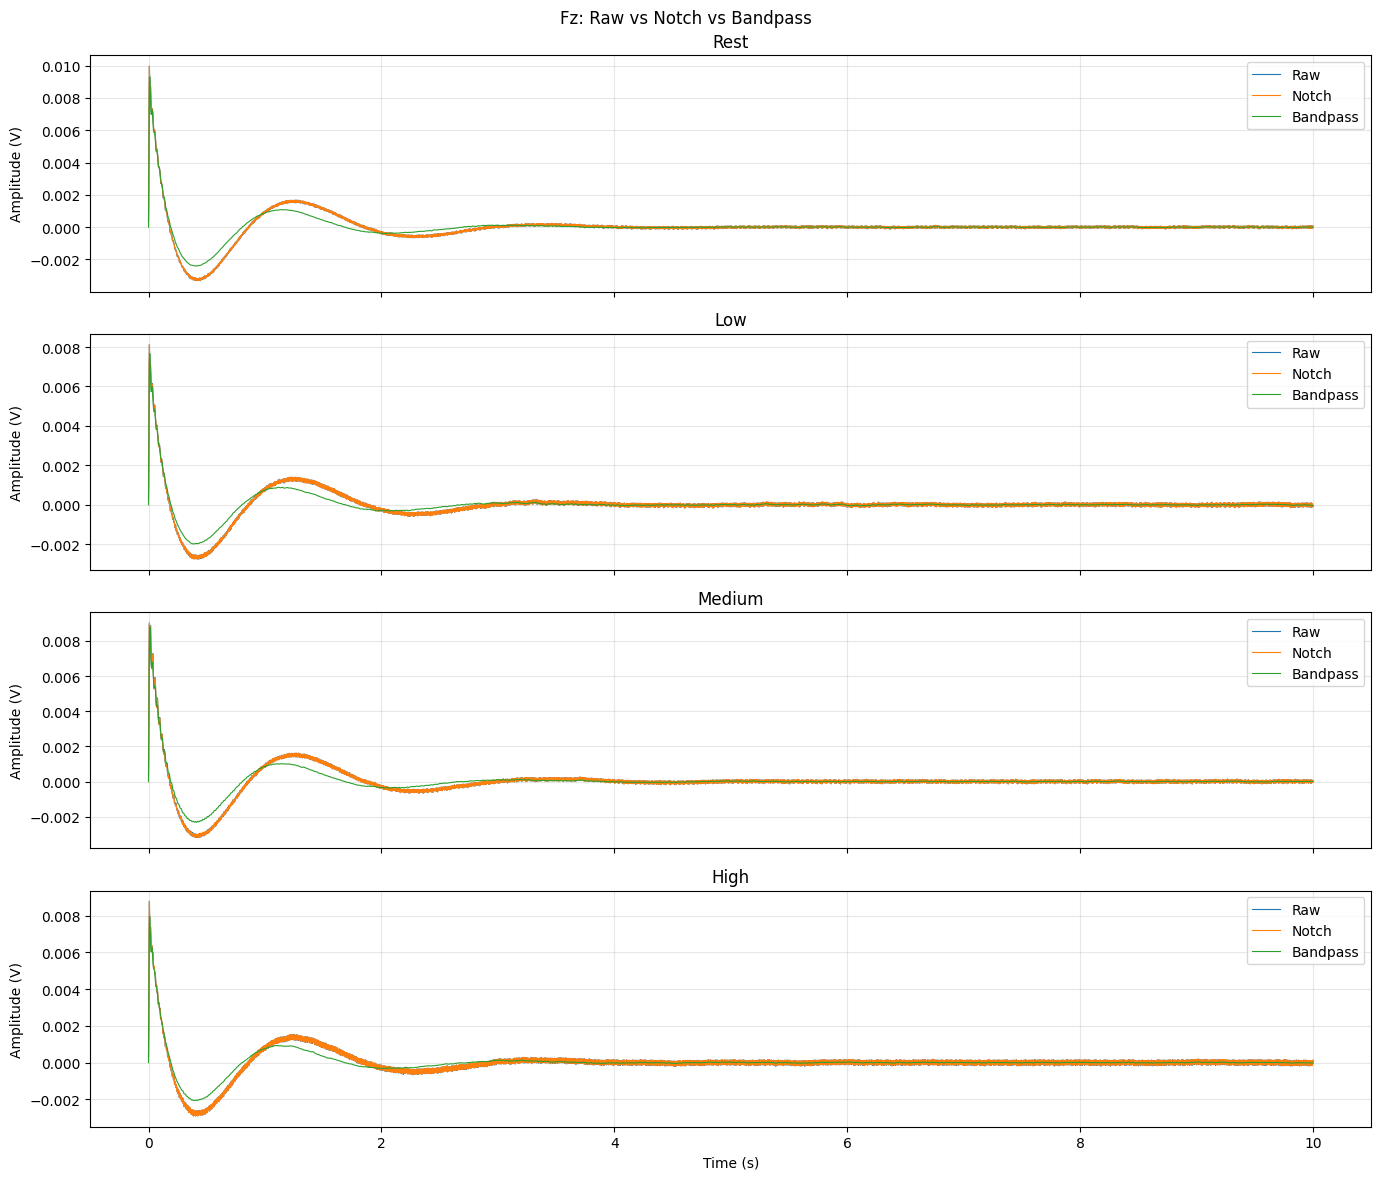

Time-domain comparison saved.


In [68]:
conditions = ["Rest", "Low", "Medium", "High"]
channel = "Fz"
start, duration = 0, 10

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

for ax, condition in zip(axes, conditions):
    signals = [
        ("Raw", raws[condition]),
        ("Notch", raws_notch[condition]),
        ("Bandpass", raws_clean[condition]),
    ]

    for label, raw in signals:
        if channel not in raw.ch_names:
            print(f"{condition}: {channel} not found")
            continue

        data = raw.get_data(
            picks=[channel],
            start=int(start * raw.info["sfreq"]),
            stop=int((start + duration) * raw.info["sfreq"])
        )[0]

        times = np.arange(len(data)) / raw.info["sfreq"] + start
        ax.plot(times, data, label=label, linewidth=0.8)

    ax.set_title(condition)
    ax.set_ylabel("Amplitude (V)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Fz: Raw vs Notch vs Bandpass")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "Raw_Notch_Bandpass_time_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Time-domain comparison saved.")

In [69]:
for name, obj in list(globals().items()):
    if not name.startswith("_") and any(
        key in name.lower()
        for key in ["fir", "iir", "causal", "zero", "filtered"]
    ):
        print(name, type(obj).__name__)

filtered RawEDF
firwin function
fir_order int
b_fir ndarray
b_iir ndarray
a_iir ndarray
freq_fir ndarray
h_fir ndarray
freq_iir ndarray
h_iir ndarray
fir_causal_db ndarray
fir_zero_db ndarray
iir_causal_db ndarray
iir_zero_db ndarray
filtered_signal ndarray


In [70]:

from scipy.signal import firwin, butter, lfilter, filtfilt
from pathlib import Path
import numpy as np

Fs = 512.0
fir_order = 330


b_fir = firwin(
    fir_order + 1,
    [1, 45],
    pass_zero=False,
    fs=Fs,
    window="hamming"
)


b_iir, a_iir = butter(
    4,
    [1, 45],
    btype="bandpass",
    fs=Fs
)

filter_outputs = {}

for condition in ["Rest", "Low", "Medium", "High"]:
    raw = raws[condition]
    data = raw.get_data()

    filter_outputs[condition] = {
        "FIR_causal": lfilter(b_fir, [1.0], data, axis=1),
        "FIR_zero_phase": filtfilt(b_fir, [1.0], data, axis=1),
        "IIR_causal": lfilter(b_iir, a_iir, data, axis=1),
        "IIR_zero_phase": filtfilt(b_iir, a_iir, data, axis=1),
    }

    print(f"{condition}: four filter outputs created")

print("All four methods completed for all conditions.")


Rest: four filter outputs created
Low: four filter outputs created
Medium: four filter outputs created
High: four filter outputs created
All four methods completed for all conditions.


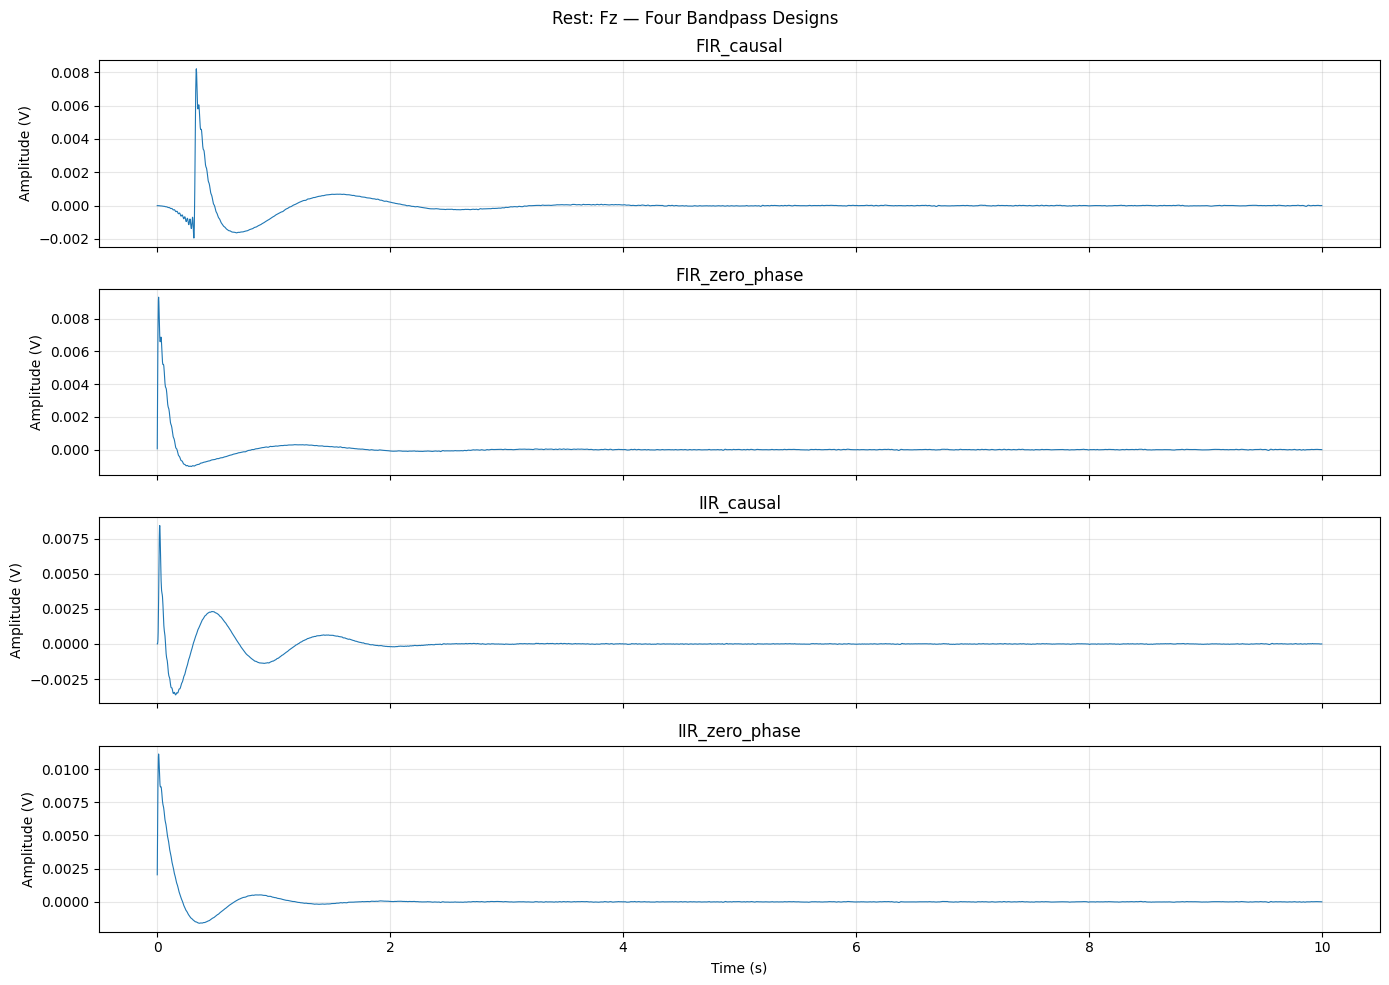

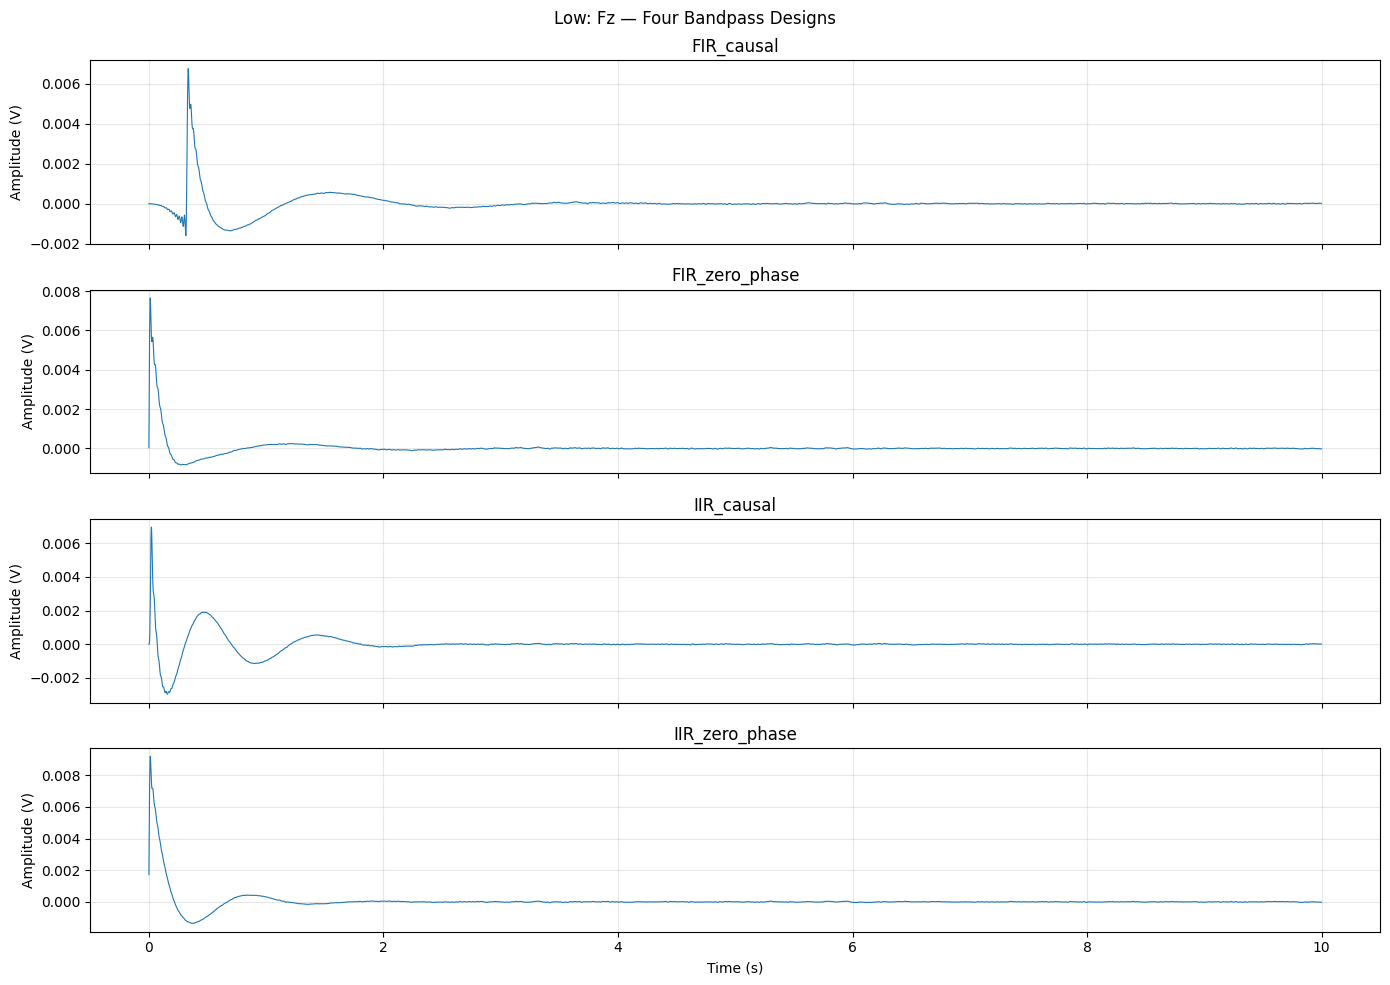

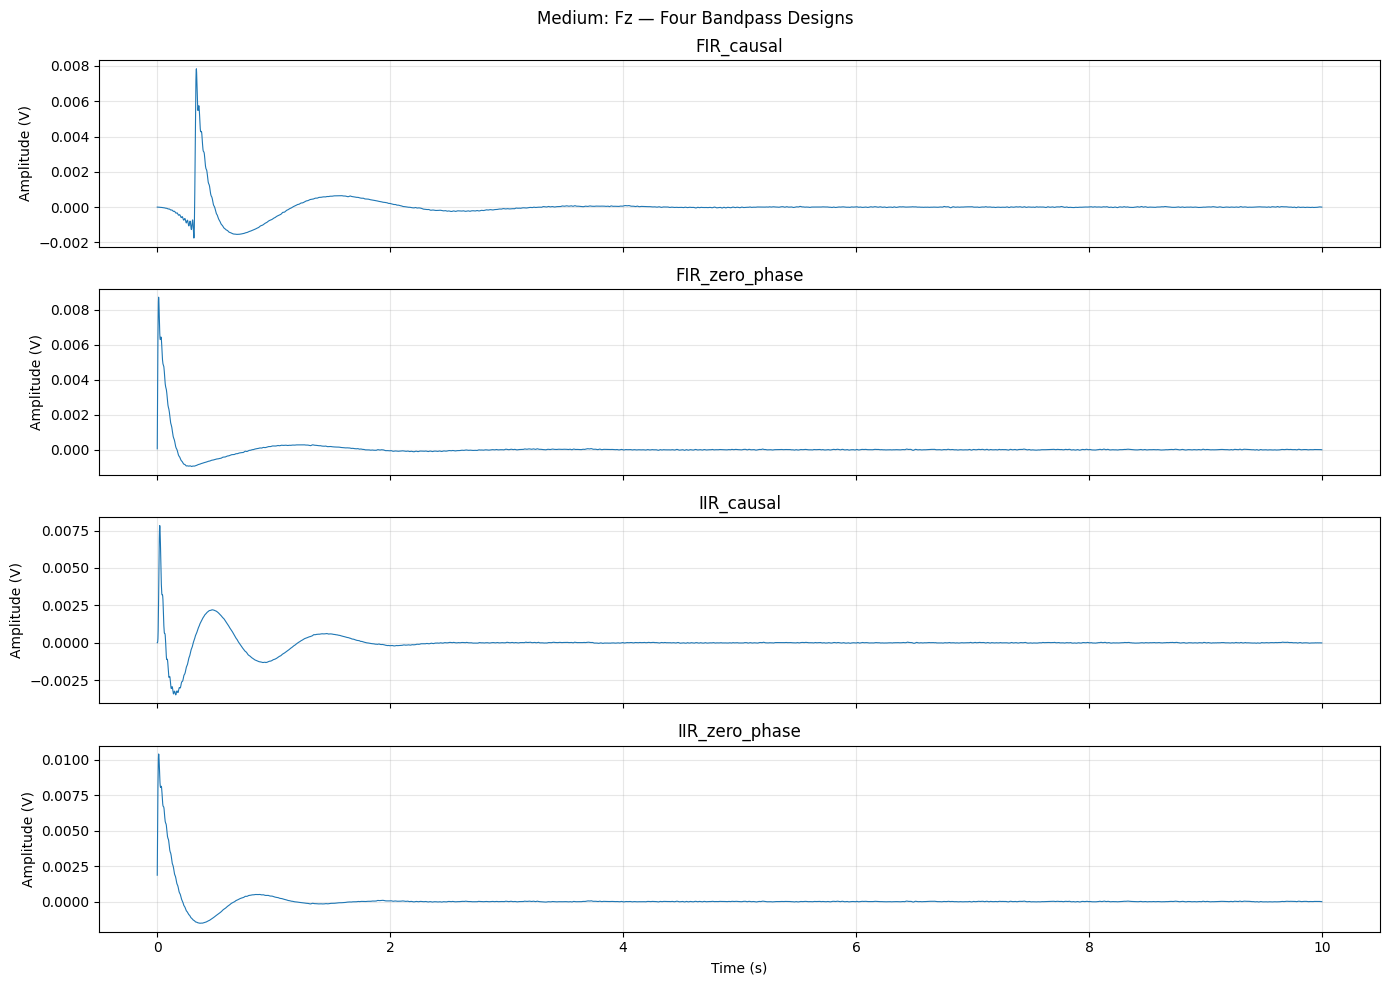

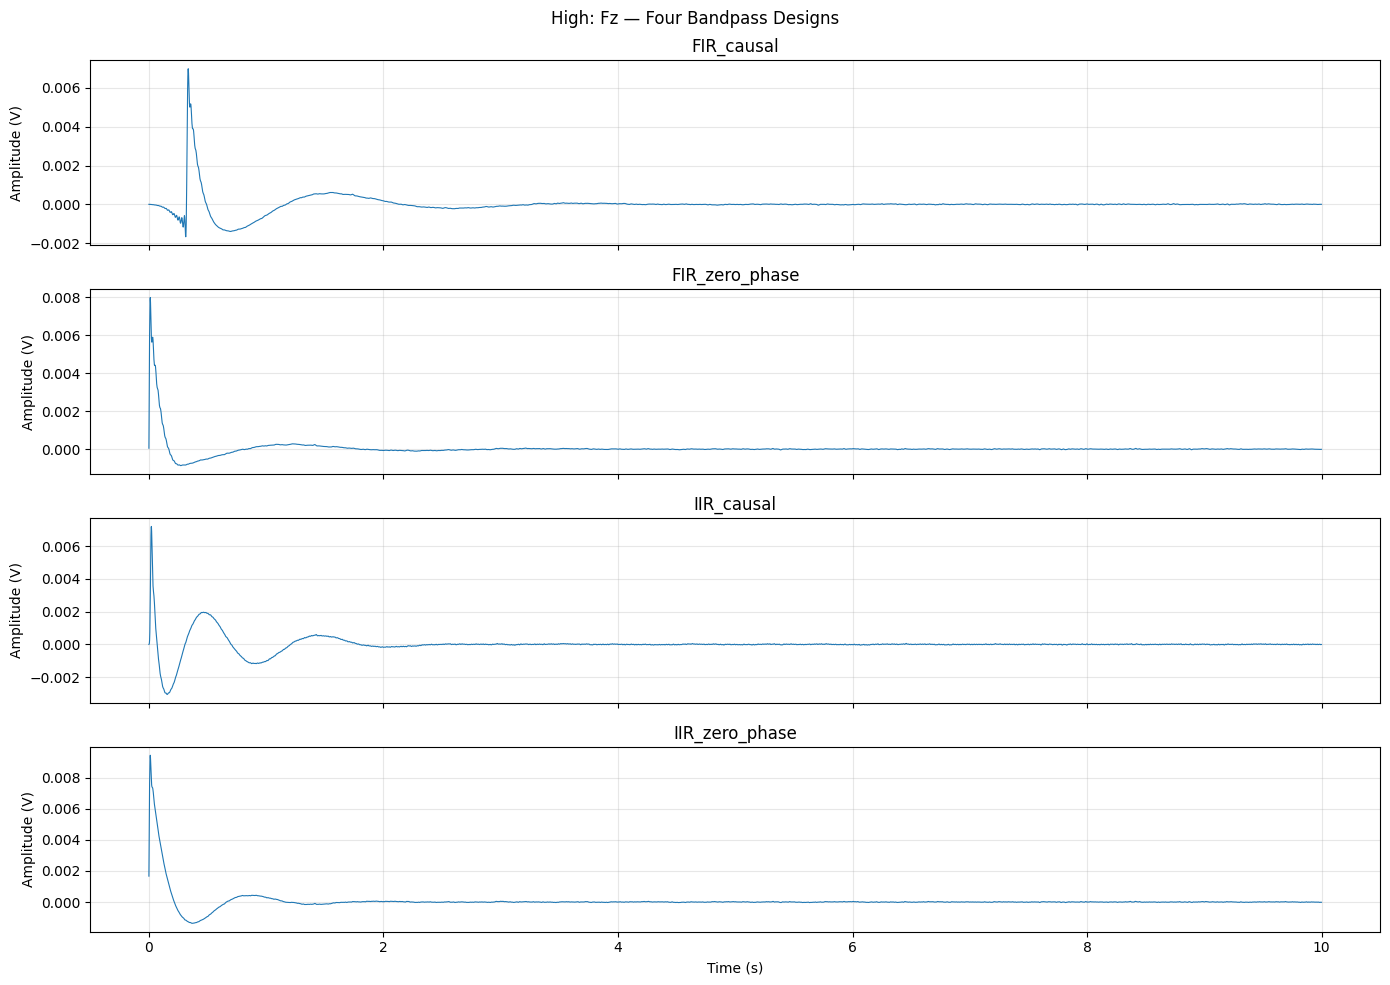

Four-filter time comparisons saved.


In [71]:

import matplotlib.pyplot as plt
import numpy as np

conditions = ["Rest", "Low", "Medium", "High"]
filter_names = [
    "FIR_causal",
    "FIR_zero_phase",
    "IIR_causal",
    "IIR_zero_phase",
]

channel = "Fz"
duration = 10

for condition in conditions:
    raw = raws[condition]
    sfreq = raw.info["sfreq"]
    channel_idx = raw.ch_names.index(channel)

    start = 0
    stop = int(duration * sfreq)
    times = np.arange(stop) / sfreq

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

    for ax, filter_name in zip(axes, filter_names):
        signal_data = filter_outputs[condition][filter_name][channel_idx, start:stop]

        ax.plot(times, signal_data, linewidth=0.8)
        ax.set_title(filter_name)
        ax.set_ylabel("Amplitude (V)")
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(f"{condition}: Fz — Four Bandpass Designs")
    plt.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"{condition}_four_filter_time_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Four-filter time comparisons saved.")


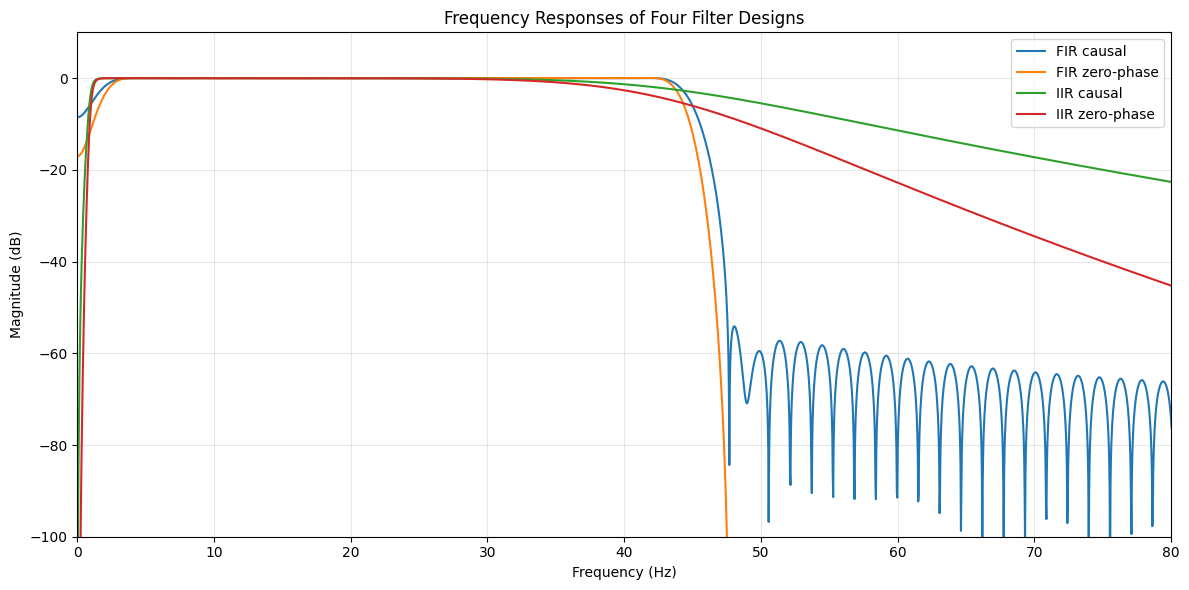

Frequency-response comparison saved.


In [72]:
freq_fir, h_fir = freqz(b_fir, worN=8192, fs=Fs)


freq_iir, h_iir = freqz(b_iir, a_iir, worN=8192, fs=Fs)


fir_causal_db = 20 * np.log10(np.maximum(np.abs(h_fir), 1e-12))
fir_zero_db = 20 * np.log10(np.maximum(np.abs(h_fir) ** 2, 1e-12))

iir_causal_db = 20 * np.log10(np.maximum(np.abs(h_iir), 1e-12))
iir_zero_db = 20 * np.log10(np.maximum(np.abs(h_iir) ** 2, 1e-12))

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(freq_fir, fir_causal_db, label="FIR causal")
ax.plot(freq_fir, fir_zero_db, label="FIR zero-phase")
ax.plot(freq_iir, iir_causal_db, label="IIR causal")
ax.plot(freq_iir, iir_zero_db, label="IIR zero-phase")

ax.set_xlim(0, 80)
ax.set_ylim(-100, 10)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_title("Frequency Responses of Four Filter Designs")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "Four_filter_magnitude_responses.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Frequency-response comparison saved.")


In [73]:
conditions = ["Rest", "Low", "Medium", "High"]
channel = "Fz"

lag_results = []

for condition in conditions:
    raw = raws[condition]
    sfreq = raw.info["sfreq"]
    ch_idx = raw.ch_names.index(channel)

    # Use a middle segment to reduce edge effects
    start = int(30 * sfreq)
    stop = int(40 * sfreq)

    original = raw.get_data(
        picks=[channel], start=start, stop=stop
    )[0]

    for filter_name in ["FIR_causal", "IIR_causal"]:
        filtered_signal = filter_outputs[condition][filter_name][ch_idx, start:stop]

        # Remove the mean before cross-correlation
        x = original - np.mean(original)
        y = filtered_signal - np.mean(filtered_signal)

        corr = correlate(y, x, mode="full", method="fft")
        lags = correlation_lags(len(y), len(x), mode="full")
        lag_samples = int(lags[np.argmax(corr)])

        lag_results.append({
            "Condition": condition,
            "Filter": filter_name,
            "Lag_samples": lag_samples,
            "Lag_ms": lag_samples / sfreq * 1000
        })

lag_df = pd.DataFrame(lag_results)
display(lag_df)

lag_df.to_csv(
    FIGURES_DIR.parent / "filter_delay_estimates.csv",
    index=False
)

print("Saved: filter_delay_estimates.csv")


,Condition,Filter,Lag_samples,Lag_ms
0,Rest,FIR_causal,165,322.265625
1,Rest,IIR_causal,4,7.812500
2,Low,FIR_causal,165,322.265625
3,Low,IIR_causal,4,7.812500
4,Medium,FIR_causal,165,322.265625
5,Medium,IIR_causal,4,7.812500
6,High,FIR_causal,165,322.265625
7,High,IIR_causal,4,7.812500


Saved: filter_delay_estimates.csv


In [74]:
condition = "Rest"
channel = "Fz"
raw = raws[condition]
sfreq = raw.info["sfreq"]
ch_idx = raw.ch_names.index(channel)

segments = {
    "Start_1s": (0, 1),
    "Middle_1s": (30, 31),
    "End_1s": (
        raw.n_times / sfreq - 1,
        raw.n_times / sfreq
    )
}

rows = []

for filter_name, data in filter_outputs[condition].items():
    for segment_name, (t0, t1) in segments.items():
        start = int(t0 * sfreq)
        stop = min(int(t1 * sfreq), data.shape[1])
        x = data[ch_idx, start:stop]

        rows.append({
            "Condition": condition,
            "Channel": channel,
            "Filter": filter_name,
            "Segment": segment_name,
            "RMS": float(np.sqrt(np.mean(x ** 2)))
        })

edge_df = pd.DataFrame(rows)
display(edge_df)

edge_df.to_csv(
    FIGURES_DIR.parent / "Rest_Fz_edge_effects.csv",
    index=False
)

print("Saved: Rest_Fz_edge_effects.csv")


,Condition,Channel,Filter,Segment,RMS
0,Rest,Fz,FIR_causal,Start_1s,0.001871
1,Rest,Fz,FIR_causal,Middle_1s,0.000012
2,Rest,Fz,FIR_causal,End_1s,0.000009
3,Rest,Fz,FIR_zero_phase,Start_1s,0.001851
4,Rest,Fz,FIR_zero_phase,Middle_1s,0.000010
5,Rest,Fz,FIR_zero_phase,End_1s,0.000007
6,Rest,Fz,IIR_causal,Start_1s,0.002029
7,Rest,Fz,IIR_causal,Middle_1s,0.000012
8,Rest,Fz,IIR_causal,End_1s,0.000008
9,Rest,Fz,IIR_zero_phase,Start_1s,0.002598


Saved: Rest_Fz_edge_effects.csv


In [75]:
conditions = ["Rest", "Low", "Medium", "High"]
filter_names = [
    "FIR_causal",
    "FIR_zero_phase",
    "IIR_causal",
    "IIR_zero_phase"
]
channel = "Fz"

rows = []

for condition in conditions:
    raw = raws[condition]
    sfreq = raw.info["sfreq"]
    ch_idx = raw.ch_names.index(channel)
    n_samples = raw.n_times
    duration = n_samples / sfreq

    segments = {
        "Start_1s": (0, 1),
        "Middle_1s": (30, 31),
        "End_1s": (duration - 1, duration)
    }

    for filter_name in filter_names:
        data = filter_outputs[condition][filter_name]

        for segment_name, (t0, t1) in segments.items():
            start = max(0, int(t0 * sfreq))
            stop = min(int(t1 * sfreq), n_samples)
            x = data[ch_idx, start:stop]

            rows.append({
                "Condition": condition,
                "Channel": channel,
                "Filter": filter_name,
                "Segment": segment_name,
                "RMS": float(np.sqrt(np.mean(x ** 2)))
            })

edge_all_df = pd.DataFrame(rows)
display(edge_all_df)

edge_all_df.to_csv(
    FIGURES_DIR.parent / "All_conditions_Fz_edge_effects.csv",
    index=False
)

print("Saved: All_conditions_Fz_edge_effects.csv")


,Condition,Channel,Filter,Segment,RMS
0,Rest,Fz,FIR_causal,Start_1s,0.001871
1,Rest,Fz,FIR_causal,Middle_1s,0.000012
2,Rest,Fz,FIR_causal,End_1s,0.000009
3,Rest,Fz,FIR_zero_phase,Start_1s,0.001851
4,Rest,Fz,FIR_zero_phase,Middle_1s,0.000010
5,Rest,Fz,FIR_zero_phase,End_1s,0.000007
6,Rest,Fz,IIR_causal,Start_1s,0.002029
7,Rest,Fz,IIR_causal,Middle_1s,0.000012
8,Rest,Fz,IIR_causal,End_1s,0.000008
9,Rest,Fz,IIR_zero_phase,Start_1s,0.002598


Saved: All_conditions_Fz_edge_effects.csv


In [76]:
conditions = ["Rest", "Low", "Medium", "High"]

bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

rows = []

for condition in conditions:
    raw = raws[condition]
    sfreq = raw.info["sfreq"]
    channel_names = raw.ch_names

    data = filter_outputs[condition]["FIR_zero_phase"]

    for ch_idx, channel_name in enumerate(channel_names):
        freqs, psd = welch(
            data[ch_idx],
            fs=sfreq,
            nperseg=2048,
            noverlap=1024
        )

        for band_name, (fmin, fmax) in bands.items():
            mask = (freqs >= fmin) & (freqs <= fmax)
            absolute_power = np.trapezoid(psd[mask], freqs[mask])

            rows.append({
                "Condition": condition,
                "Channel": channel_name,
                "Band": band_name,
                "Absolute_Power": absolute_power
            })

absolute_band_power_df = pd.DataFrame(rows)

absolute_band_power_df.to_csv(
    FIGURES_DIR.parent / "absolute_band_power_four_conditions.csv",
    index=False
)

print("Saved: absolute_band_power_four_conditions.csv")
display(absolute_band_power_df.head())


Saved: absolute_band_power_four_conditions.csv


,Condition,Channel,Band,Absolute_Power
0,Rest,Fp1,Delta,7.573717e-11
1,Rest,Fp1,Theta,3.188706e-11
2,Rest,Fp1,Alpha,1.174945e-11
3,Rest,Fp1,Beta,3.120985e-11
4,Rest,Fp1,Gamma,8.487767e-12


In [77]:
power_df = pd.read_csv(
    FIGURES_DIR.parent / "absolute_band_power_four_conditions.csv"
)

summary = (
    power_df
    .groupby(["Condition", "Band"])["Absolute_Power"]
    .mean()
    .unstack("Band")
    .reindex(["Rest", "Low", "Medium", "High"])
)

display(summary.round(3))

summary.to_csv(
    FIGURES_DIR.parent / "mean_absolute_band_power_by_condition.csv"
)

print("Saved: mean_absolute_band_power_by_condition.csv")

Band,Alpha,Beta,Delta,Gamma,Theta
Condition,,,,,
Rest,0.0,0.0,0.0,0.0,0.0
Low,0.0,0.0,0.0,0.0,0.0
Medium,0.0,0.0,0.0,0.0,0.0
High,0.0,0.0,0.0,0.0,0.0


Saved: mean_absolute_band_power_by_condition.csv


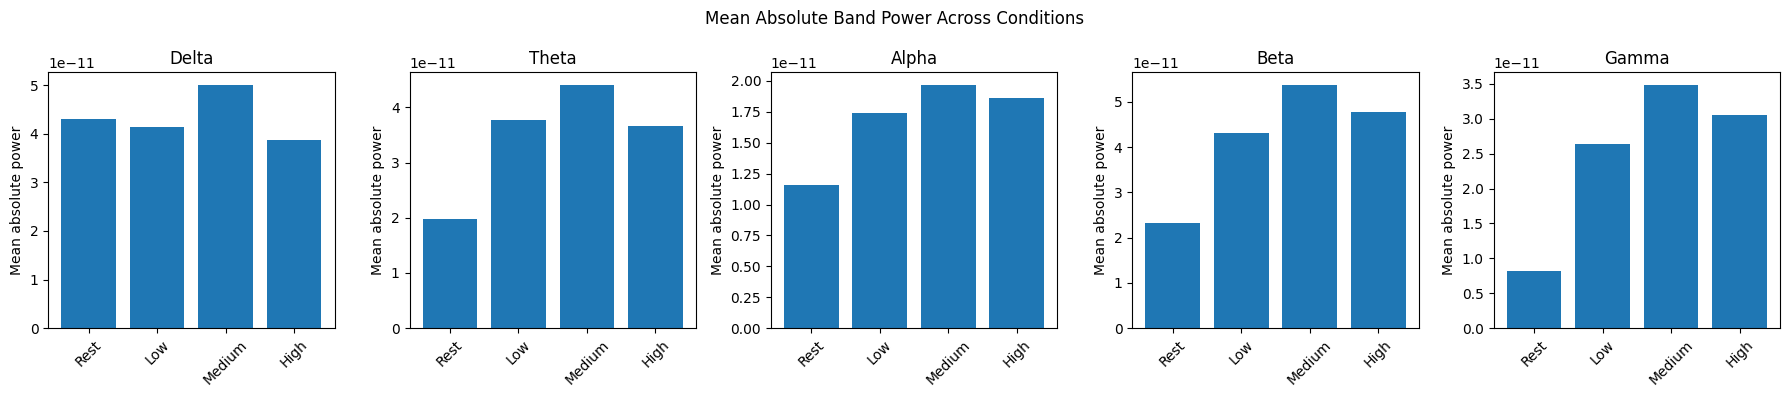

Saved: /content/drive/MyDrive/Colab Notebooks/Assignment-02/figures/Mean_Absolute_Band_Power_Comparison.png


In [78]:
bands_order = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, band in zip(axes, bands_order):
    ax.bar(summary.index, summary[band])
    ax.set_title(band)
    ax.set_ylabel("Mean absolute power")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Mean Absolute Band Power Across Conditions")
fig.tight_layout()

output_path = FIGURES_DIR / "Mean_Absolute_Band_Power_Comparison.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path}")

In [79]:
percentage_change = (
    (summary.loc[["Low", "Medium", "High"]] - summary.loc["Rest"])
    / summary.loc["Rest"].replace(0, float("nan"))
) * 100

percentage_change = percentage_change.reindex(["Low", "Medium", "High"])
display(percentage_change.round(1))

percentage_change.to_csv(
    FIGURES_DIR.parent / "band_power_percentage_change_vs_rest.csv"
)

print("Saved: band_power_percentage_change_vs_rest.csv")

Band,Alpha,Beta,Delta,Gamma,Theta
Condition,,,,,
Low,50.5,84.8,-3.7,220.0,91.6
Medium,70.3,131.2,16.4,323.3,123.8
High,61.0,105.3,-10.2,269.5,86.0


Saved: band_power_percentage_change_vs_rest.csv


In [80]:
output_dir = Path(FIGURES_DIR).parent
delay_df = pd.read_csv(output_dir / "filter_delay_estimates.csv")

display(delay_df.round(3))

,Condition,Filter,Lag_samples,Lag_ms
0,Rest,FIR_causal,165,322.266
1,Rest,IIR_causal,4,7.812
2,Low,FIR_causal,165,322.266
3,Low,IIR_causal,4,7.812
4,Medium,FIR_causal,165,322.266
5,Medium,IIR_causal,4,7.812
6,High,FIR_causal,165,322.266
7,High,IIR_causal,4,7.812
